# 06 · Explaining the late-delivery model

**Question:** Which purchase-time features push an order's late-delivery risk up
or down in the LightGBM model?

The model is trained exactly as in `src/train.py` (train before Mar 2018, early
stopping on Mar-Apr 2018). It is explained on the test set (May-Aug 2018), the
orders it never saw.

**How to read SHAP values.** Every order starts at the model's average score.
Each feature then gives a push: positive = toward *late*, negative = toward
*on time*. The pushes add up to the order's final score. Scores are in
log-odds (the model's internal scale), so compare the sizes of the pushes
with each other rather than reading them as percentages.

In [5]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

# Notebooks run from notebooks/, so add src/ to the import path.
sys.path.insert(0, str(Path.cwd().parent / "src"))
from features import TARGET, load_features
from train import FEATURES, fit_lightgbm, time_split

FIGURES = Path.cwd().parent / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

df = load_features()
train, valid, test = time_split(df)
model = fit_lightgbm(train, valid)
print(f"LightGBM stopped at {model.best_iteration_} trees")

X_test = test[FEATURES]
risk = model.predict_proba(X_test)[:, 1]
shap_values = shap.TreeExplainer(model)(X_test)
print(f"SHAP values: {shap_values.values.shape[0]:,} orders x {shap_values.values.shape[1]} features")

LightGBM stopped at 111 trees
SHAP values: 25,352 orders x 21 features


## 1. Overall importance

**Question:** Which features does the model lean on most?

Bar length = the average size of a feature's push across all test orders,
ignoring direction.

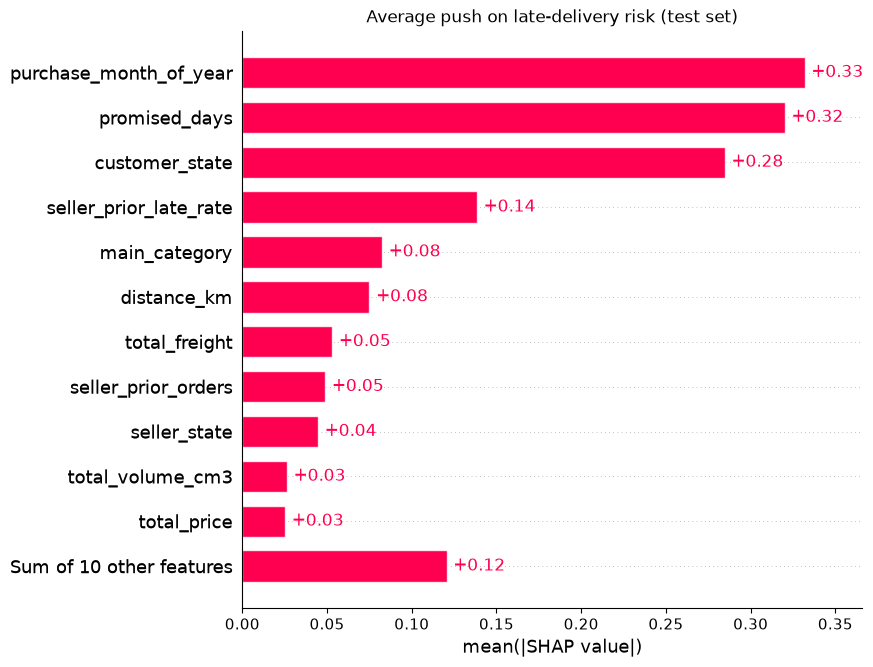

In [6]:
shap.plots.bar(shap_values, max_display=12, show=False)
plt.title("Average push on late-delivery risk (test set)")
plt.savefig(FIGURES / "06_shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations:**

- _your notes_

## 2. Direction of each push

**Question:** For each numeric feature, do high values push toward late or
toward on time?

One dot per order. Horizontal position = the push. Colour = the feature's
value (red high, blue low). Grey rows are categorical features, which have no
"high" or "low"; section 3 covers them.

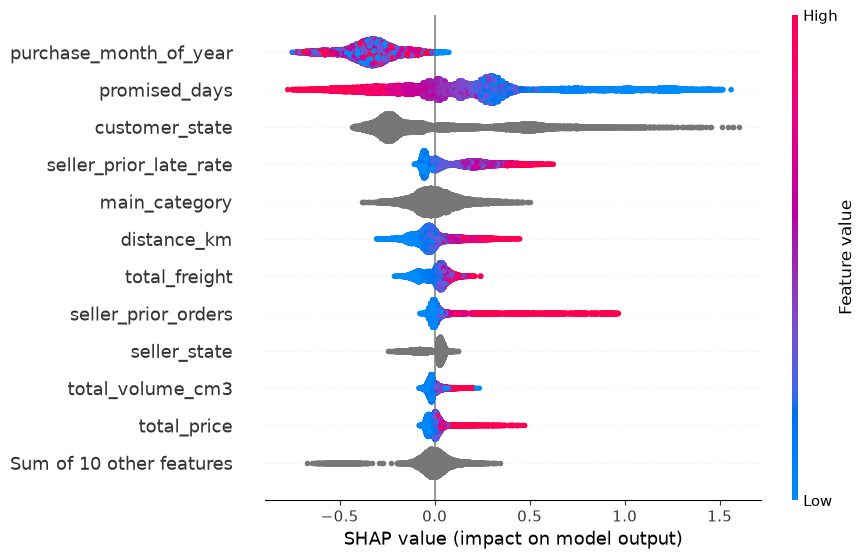

In [7]:
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.savefig(FIGURES / "06_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations:**

- _your notes_

## 3. Customer state

**Question:** Which delivery states does the model push toward late, and which
toward on time?

Average push per state, with the state's order count and actual late rate in
the test set for comparison.

In [8]:
state_push = (
    pd.DataFrame({
        "customer_state": test["customer_state"].astype(str).values,
        "push": shap_values[:, "customer_state"].values,
        "is_late": test[TARGET].values,
    })
    .groupby("customer_state")
    .agg(orders=("push", "size"), avg_push=("push", "mean"), late_rate=("is_late", "mean"))
    .sort_values("avg_push", ascending=False)
    .round(3)
)
state_push

,orders,avg_push,late_rate
customer_state,,,
AL,81,1.203,0.074
PB,136,0.930,0.044
MA,141,0.883,0.113
SE,82,0.845,0.049
PE,412,0.699,0.063
BA,839,0.645,0.088
RN,106,0.547,0.009
CE,283,0.471,0.032
PA,194,0.457,0.041


**Observations:**

- _your notes_

## 4. One order, explained

**Question:** Why did the model give its riskiest test order a high score?

The waterfall starts at the average score `E[f(X)]` (bottom) and adds one push
per feature until it reaches this order's score `f(x)` (top).

Order 7e225c7be8d238e6c940f116d7583a13: predicted risk 44.0%, actually late: False


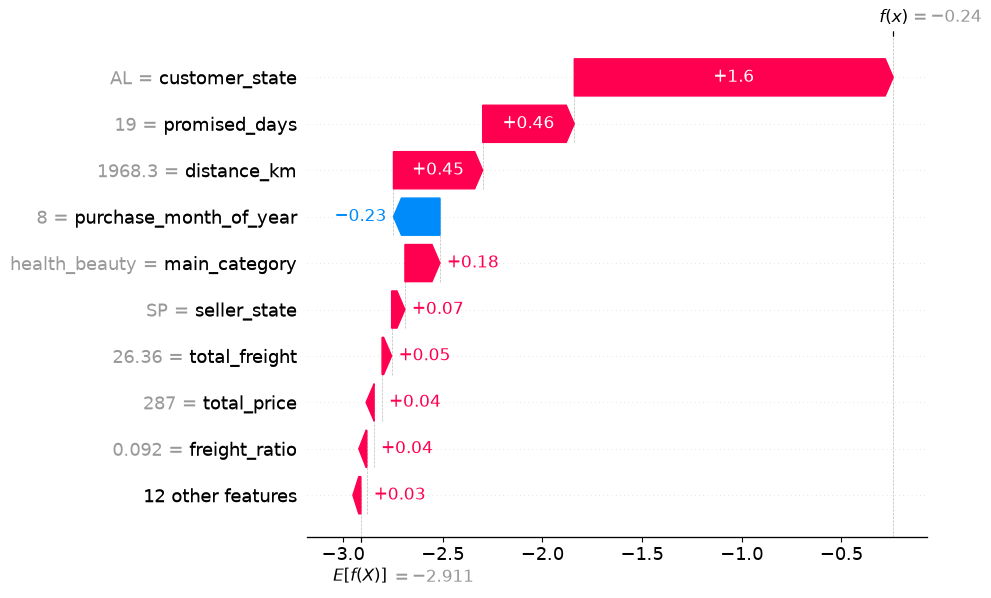

In [9]:
top = int(np.argmax(risk))
print(f"Order {test['order_id'].iloc[top]}: predicted risk {risk[top]:.1%}, "
      f"actually late: {bool(test[TARGET].iloc[top])}")

shap.plots.waterfall(shap_values[top], max_display=10, show=False)
plt.savefig(FIGURES / "06_shap_top_order.png", dpi=150, bbox_inches="tight")
plt.show()